[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

练习基础、角度、振幅和稀疏编码，并读取态矢量。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。

# 量子态制备与编码

- 基础编码`basic_encode`：编码到计算基态
- 角度编码`angle_encode`：编码到旋转门的角度参数
- 振幅编码`amplitude_encode`：编码到量子态的振幅 
- 稀疏编码`sparse_isometry`：编码稀疏量子态

## 1.基础编码

In [1]:
from pyqpanda3.core import Encode, QProg, measure, CPUQVM, draw_qprog

In [2]:
enc = Encode()
enc.basic_encode([0, 1, 2], "101")

In [3]:
prog = QProg()
prog << enc.get_circuit() << measure([0, 1, 2], [0, 1, 2])

┌─┐      ┌─┐     
q_0:  |0>─┤X├──── ─┤M├──── 
          └─┘ ┌─┐  └╥┘     
q_1:  |0>─────┤M├ ──╫───── 
          ┌─┐ └╥┘   ║  ┌─┐ 
q_2:  |0>─┤X├──╫─ ──╫──┤M├ 
          └─┘  ║    ║  └╥┘ 
 c :   / ══════╩════╩═══╩═
                1    0   2

In [4]:
machine = CPUQVM()
machine.run(prog, 1000)
print(machine.result().get_counts())  # {'101': 1000}

{'101': 1000}


## 2.角度编码

In [5]:
from pyqpanda3.core import Encode, GateType, QProg, measure, CPUQVM, draw_qprog

In [6]:
# 默认使用 RY 门
enc = Encode()
enc.angle_encode([0, 1, 2], [0.5, 1.0, 1.5])

In [7]:
prog = QProg()
prog << enc.get_circuit() << measure([0, 1, 2], [0, 1, 2])

┌──┐  ┌─┐         
q_0:  |0>─┤RY├ ─┤M├──────── 
          ├──┤  └╥┘ ┌─┐     
q_1:  |0>─┤RY├ ──╫──┤M├──── 
          ├──┤   ║  └╥┘ ┌─┐ 
q_2:  |0>─┤RY├ ──╫───╫──┤M├ 
          └──┘   ║   ║  └╥┘ 
 c :   / ════════╩═══╩═══╩═
                  0   1   2

In [8]:
print(draw_qprog(prog, param_show=True))


          ┌──────────────┐  ┌─┐         
q_0:  |0>─┤RY(0.50000000)├ ─┤M├──────── 
          ├──────────────┤  └╥┘ ┌─┐     
q_1:  |0>─┤RY(1.00000000)├ ──╫──┤M├──── 
          ├──────────────┤   ║  └╥┘ ┌─┐ 
q_2:  |0>─┤RY(1.50000000)├ ──╫───╫──┤M├ 
          └──────────────┘   ║   ║  └╥┘ 
 c :   / ════════════════════╩═══╩═══╩═
                              0   1   2




In [9]:
machine = CPUQVM()
machine.run(prog, 1000)
print(machine.result().get_counts())

{'101': 24, '000': 389, '100': 318, '001': 25, '010': 129, '011': 6, '110': 106, '111': 3}


**注**：也可以使用 RX门

In [10]:
# 使用 RX 门
enc2 = Encode()
enc2.angle_encode([0, 1, 2], [0.5, 1.0, 1.5], GateType.RX)
print(draw_qprog(enc2.get_circuit(), param_show=True))


          ┌──────────────┐ 
q_0:  |0>─┤RX(0.50000000)├ 
          ├──────────────┤ 
q_1:  |0>─┤RX(1.00000000)├ 
          ├──────────────┤ 
q_2:  |0>─┤RX(1.50000000)├ 
          └──────────────┘ 
 c :   / ═════════════════
                          




## 3.振幅编码

In [11]:
import numpy as np
from pyqpanda3.core import Encode, QProg, measure, CPUQVM
from pyqpanda3.core import draw_qprog

In [12]:
# 实数值：等叠加态
enc = Encode()
enc.amplitude_encode([0, 1], [0.5, 0.5, 0.5, 0.5])

In [13]:
# 运行
prog = QProg()
prog << enc.get_circuit() << measure([0, 1], [0, 1])

┌──┐     ┌──┐     ┌─┐      
q_0:  |0>───── ┤RY├ ─── ┤RY├ ────┤M├ ──── 
          ┌──┐ └─┬┘ ┌─┐ └─┬┘ ┌─┐ └╥┘  ┌─┐ 
q_1:  |0>─┤RY├ ──*─ ┤X├ ──*─ ┤X├──╫─ ─┤M├ 
          └──┘      └─┘      └─┘  ║   └╥┘ 
 c :   / ═════════════════════════╩════╩═
                                   0    1

In [14]:
print(draw_qprog(prog))
machine = CPUQVM()
machine.run(prog, 1000)
print(machine.result().get_counts())


               ┌──┐     ┌──┐     ┌─┐      
q_0:  |0>───── ┤RY├ ─── ┤RY├ ────┤M├ ──── 
          ┌──┐ └─┬┘ ┌─┐ └─┬┘ ┌─┐ └╥┘  ┌─┐ 
q_1:  |0>─┤RY├ ──*─ ┤X├ ──*─ ┤X├──╫─ ─┤M├ 
          └──┘      └─┘      └─┘  ║   └╥┘ 
 c :   / ═════════════════════════╩════╩═
                                   0    1


{'00': 243, '01': 246, '10': 244, '11': 267}


In [15]:
# 复数值
enc2 = Encode()
data = [0.5+0j, 0.5j, -0.5, 0.5-0.5j]
norm = np.linalg.norm(data)
enc2.amplitude_encode([0, 1], [complex(x/norm) for x in data])

In [16]:
prog2 = QProg()
prog2 << enc2.get_circuit() << measure([0, 1], [0, 1])

┌──┐     ┌──┐       ┌─┐      ┌─┐         ┌─┐     
q_0:  |0>───── ┤RY├ ─── ┤RY├ ─── X ┤X├ ──*─ ┤X├ ──*─ X ─┤M├──── 
          ┌──┐ └─┬┘ ┌─┐ └─┬┘ ┌─┐ │ └─┘ ┌─┴┐ └─┘ ┌─┴┐ │  └╥┘ ┌─┐ 
q_1:  |0>─┤RY├ ──*─ ┤X├ ──*─ ┤X├ X ─── ┤U4├ ─── ┤U4├ X ──╫──┤M├ 
          └──┘      └─┘      └─┘       └──┘     └──┘     ║  └╥┘ 
 c :   / ════════════════════════════════════════════════╩═══╩═
                                                          0   1

使用StateVector可以查看量子态矢量

In [17]:
from pyqpanda3.quantum_info import StateVector
init_state = StateVector(2) # |00\rangle
final_state = init_state.evolve(enc2.get_circuit())
print(final_state)

[ 4.47213595e-01+0.00000000e+00j  2.73839349e-17+4.47213595e-01j
 -4.47213595e-01+5.47678698e-17j  4.47213595e-01-4.47213595e-01j]


## 4.稀疏编码

In [18]:
import numpy as np
from pyqpanda3.core import Encode, QProg, measure, CPUQVM
from pyqpanda3.core import draw_qprog

使用字典形式指定量子态每一个分量对应的振幅，需要注意归一化

In [19]:
# 稀疏字典格式
enc = Encode()
data_dict = {"000": 0.40, "001": 0.91, "111": 0.08}
norm = sum(v**2 for v in data_dict.values()) ** 0.5
normalized_data = {k: v/norm for k, v in data_dict.items()}

In [20]:
qubits = [0, 1, 2]
enc.sparse_isometry(qubits, normalized_data)

In [21]:
prog = QProg()
prog << enc.get_circuit()
prog << measure(qubits, qubits)

┌──┐     ┌──┐ ┌─┐     ┌─┐  ┌─┐  ┌─┐     
q_0:  |0>───── ┤RY├ ─── ┤RY├ ┤X├ ─*─ ┤X├─ ┤X├ ─┤M├──── 
          ┌──┐ └─┬┘ ┌─┐ └─┬┘ ├─┤  │  └┬┴┐ └┬┘  └╥┘     
q_1:  |0>─┤RY├ ──*─ ┤X├ ──*─ ┤X├ ─*─ ─┤M├ ─┼─ ──╫───── 
          └──┘      └─┘      └─┘ ┌┴┐  └╥┘  │    ║  ┌─┐ 
q_2:  |0>───── ──── ─── ──── ─── ┤X├ ──╫─ ─*─ ──╫──┤M├ 
                                 └─┘   ║        ║  └╥┘ 
 c :   / ══════════════════════════════╩════════╩═══╩═
                                        1        0   2

In [22]:
machine = CPUQVM()
machine.run(prog, 1000)
print(machine.result().get_counts())

{'000': 154, '001': 840, '111': 6}


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

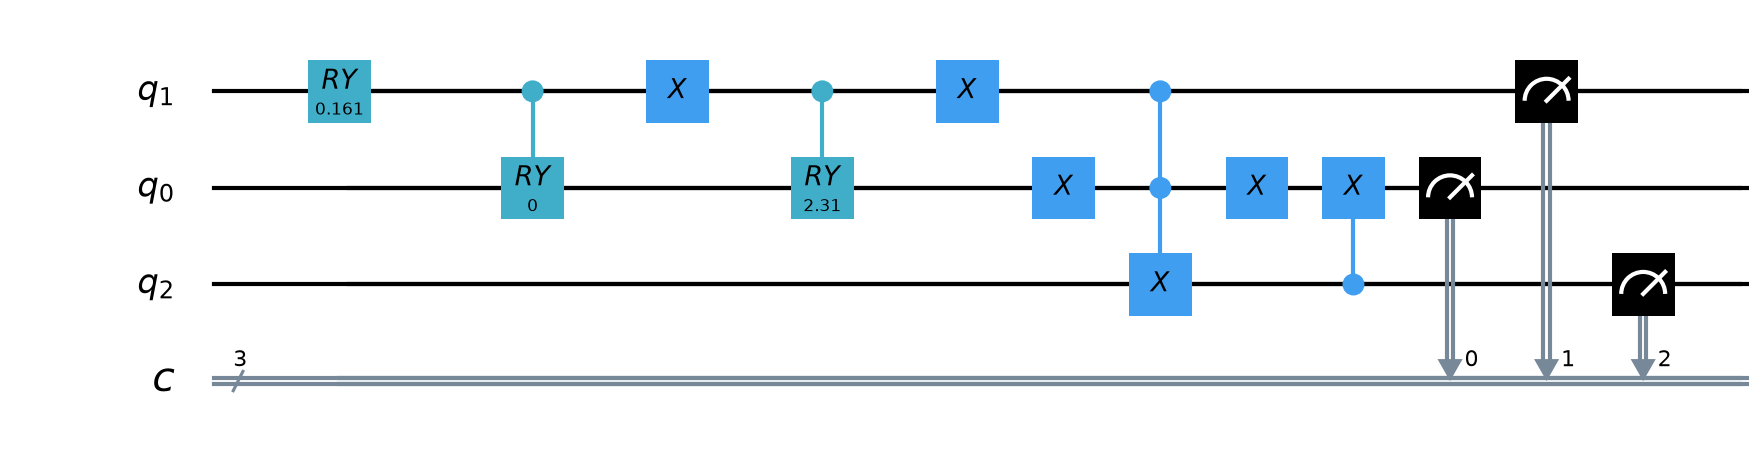

In [23]:
from pathlib import Path
from IPython.display import Image, display
import pyqpanda3.visualization

repo_root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
figure_dir = repo_root / ".tmp/notebook-figures/day1"
figure_dir.mkdir(parents=True, exist_ok=True)
image_path = figure_dir / "05_state_encoding.png"
prog.draw("pic", filename=str(image_path), with_gate_params=True)
display(Image(filename=str(image_path)))
